README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Train: (50000, 32, 32, 3) Test: (10000, 32, 32, 3)
Pixel range: 0 - 255
Mean: 120.71  Std: 64.15


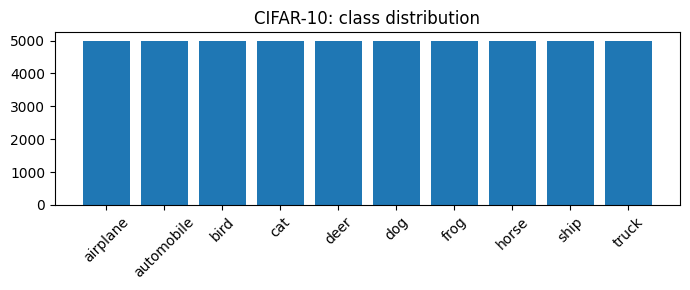

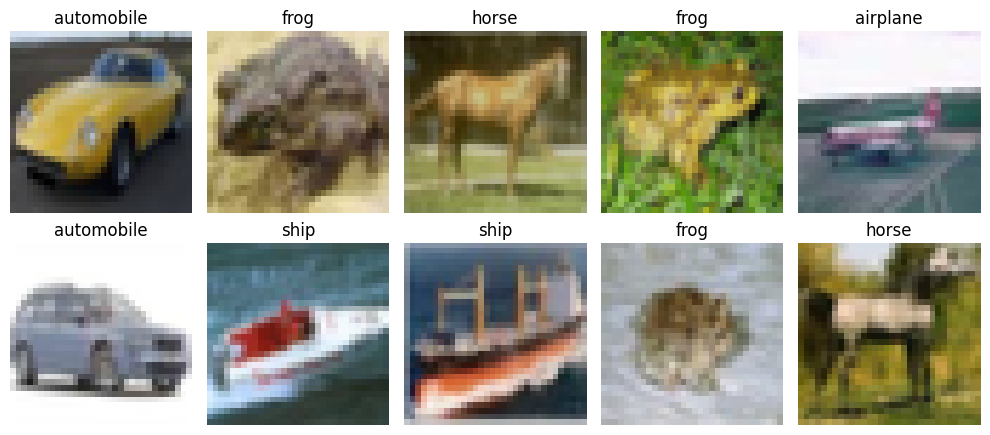

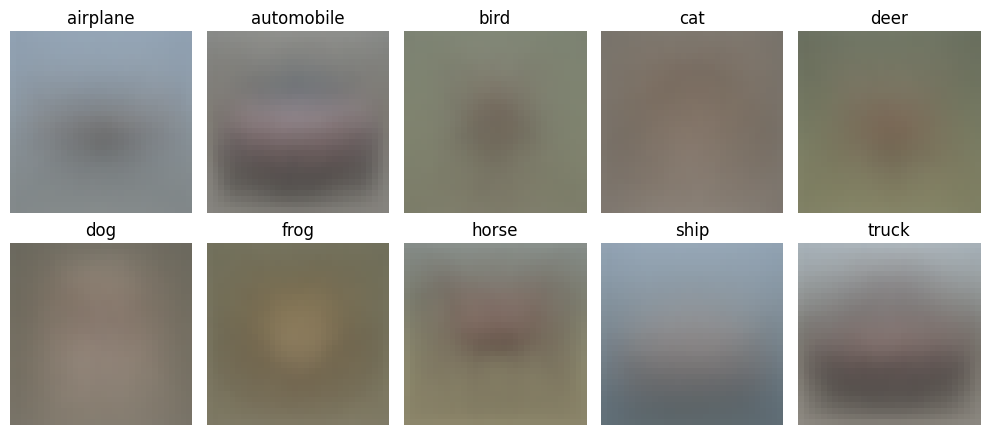

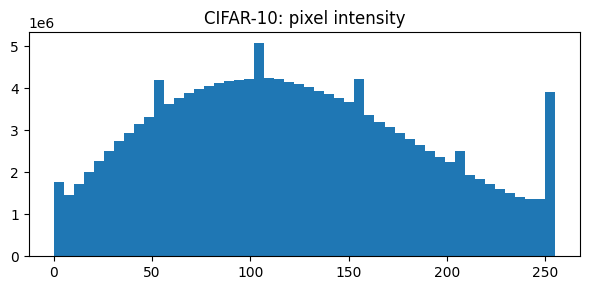

In [1]:
!pip -q install datasets
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

classes = ["airplane","automobile","bird","cat","deer",
           "dog","frog","horse","ship","truck"]

ds = load_dataset("uoft-cs/cifar10")
X_train = np.array([np.array(im) for im in ds["train"]["img"]])
y_train = np.array(ds["train"]["label"])
X_test = np.array([np.array(im) for im in ds["test"]["img"]])

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Pixel range:", X_train.min(), "-", X_train.max())
print("Mean: %.2f  Std: %.2f" % (X_train.mean(), X_train.std()))

plt.figure(figsize=(7, 3))
plt.bar(classes, np.bincount(y_train))
plt.xticks(rotation=45)
plt.title("CIFAR-10: class distribution")
plt.tight_layout()
plt.savefig("CIFAR-10_class_dist.png")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, i in zip(axes.ravel(), np.random.choice(len(X_train), 10, replace=False)):
    ax.imshow(X_train[i])
    ax.set_title(classes[y_train[i]])
    ax.axis("off")
plt.tight_layout()
plt.savefig("CIFAR-10_samples.png")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[y_train == c].mean(axis=0).astype("uint8"))
    ax.set_title(classes[c])
    ax.axis("off")
plt.tight_layout()
plt.savefig("CIFAR-10_mean_images.png")
plt.show()

plt.figure(figsize=(6, 3))
plt.hist(X_train.ravel(), bins=50)
plt.title("CIFAR-10: pixel intensity")
plt.tight_layout()
plt.savefig("CIFAR-10_pixel_hist.png")
plt.show()